# Chương 2 bài 2b EDA bán lẻ

**Nguồn:** Lab EDA, yêu cầu EDA siêu thị trong bài tập thực hành 2, trang 8

**Đề bài:** Thực hiện EDA trên tập dữ liệu mua sắm tại siêu thị/bán lẻ Online Retail.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C2_BT02b_EDA_BanLe'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Nạp và kiểm tra toàn bộ dữ liệu

In [2]:
raw = pd.read_excel(DATA / 'Online Retail.xlsx', engine='openpyxl')
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
print('Shape:', raw.shape)
print(raw.head())
print('Missing:\n', raw.isna().sum())
print('Duplicate rows:', raw.duplicated().sum())
print('Negative/zero quantities:', (raw.Quantity <= 0).sum())
print('Negative/zero prices:', (raw.UnitPrice <= 0).sum())
cancelled = raw.InvoiceNo.astype(str).str.upper().str.startswith('C')
print('Cancellation rows:', cancelled.sum())

Shape: (541909, 8)
  InvoiceNo StockCode  ... CustomerID         Country
0    536365    85123A  ...    17850.0  United Kingdom
1    536365     71053  ...    17850.0  United Kingdom
2    536365    84406B  ...    17850.0  United Kingdom
3    536365    84029G  ...    17850.0  United Kingdom
4    536365    84029E  ...    17850.0  United Kingdom

[5 rows x 8 columns]
Missing:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268
Negative/zero quantities: 10624
Negative/zero prices: 2517
Cancellation rows: 9288


## 2 Xây tập giao dịch mua hợp lệ cho phân tích

In [3]:
# Analysis view: positive purchases, not net revenue after refunds.
df = raw.drop_duplicates().copy()
df = df.loc[~df.InvoiceNo.astype(str).str.upper().str.startswith('C')]
df = df.loc[(df.Quantity > 0) & (df.UnitPrice > 0) & df.InvoiceDate.notna()].copy()
df['LineTotal'] = df.Quantity * df.UnitPrice
df['Month'] = df.InvoiceDate.dt.to_period('M').astype(str)
monthly = df.groupby('Month')['LineTotal'].sum()
countries = df.groupby('Country')['LineTotal'].sum().sort_values(ascending=False)
products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
# Customer-specific view excludes unknown customer IDs only here.
customer_df = df.dropna(subset=['CustomerID'])
print('Valid purchase rows:', len(df))
print('Purchase value (not net revenue):', round(df.LineTotal.sum(), 2))
print('Known customers:', customer_df.CustomerID.nunique())
monthly.to_csv(OUT / 'gia_tri_mua_theo_thang.csv')
countries.to_csv(OUT / 'gia_tri_mua_theo_quoc_gia.csv')

Valid purchase rows: 524878
Purchase value (not net revenue): 10642110.8
Known customers: 4338


## 3 Trực quan hóa và kết luận

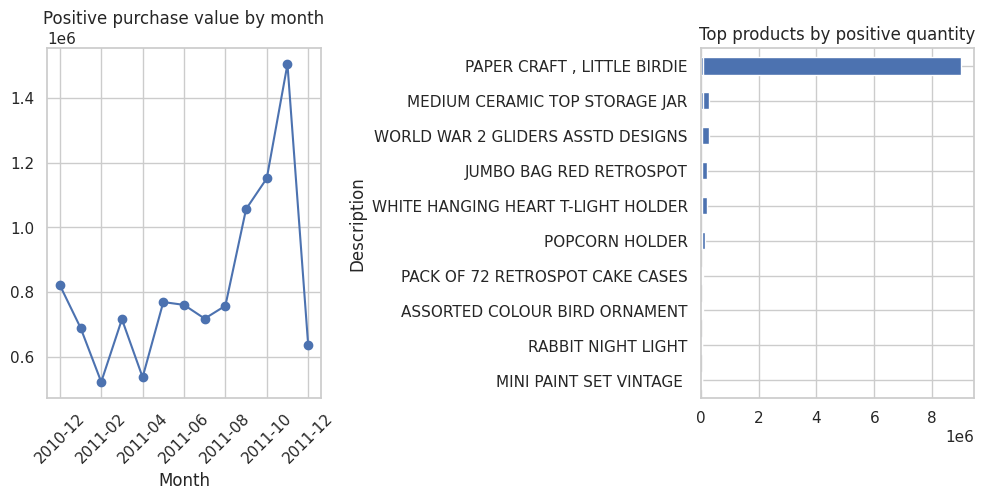

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly.plot(marker='o', ax=axes[0], title='Positive purchase value by month')
countries.head(10).sort_values().plot.barh(ax=axes[1], title='Top countries by purchase value')
axes[0].tick_params(axis='x', rotation=45)
save_fig('01_thang_quoc_gia.png')
products.sort_values().plot.barh(figsize=(10, 5), title='Top products by positive quantity')
save_fig('02_san_pham.png')
save_summary({'raw_rows':len(raw), 'raw_columns':raw.shape[1],
              'duplicate_rows':int(raw.duplicated().sum()),
              'missing_customer_rows':int(raw.CustomerID.isna().sum()),
              'cancellation_rows':int(cancelled.sum()), 'valid_purchase_rows':len(df),
              'positive_purchase_value':float(df.LineTotal.sum()),
              'known_customers':int(customer_df.CustomerID.nunique()),
              'start_date':str(df.InvoiceDate.min()), 'end_date':str(df.InvoiceDate.max()),
              'top_country':str(countries.index[0]),
              'top_country_fraction':float(countries.iloc[0]/countries.sum())})

## Nhận xét và giới hạn
Không tự điền CustomerID. Giao dịch không có ID vẫn được tính trong phân tích giá trị mua nếu hợp lệ. Các dòng hủy/âm/giá không dương bị loại khỏi góc nhìn mua hàng dương; tổng báo cáo không phải doanh thu thuần sau hoàn trả. Tháng 12/2011 chỉ có một phần tháng; không so trực tiếp như tháng trọn vẹn.